In [2]:
pip install pymoo matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 59.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 32.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


Amostra de 5 solucoes inteiras encontradas (Pods, Analistas):
Pods: 30 | Analistas: 15 => Latencia:  23.33ms | Custo: R$ 1215.00
Pods:  1 | Analistas:  1 => Latencia: 550.00ms | Custo: R$  63.00
Pods:  2 | Analistas:  1 => Latencia: 350.00ms | Custo: R$  81.00
Pods:  3 | Analistas:  1 => Latencia: 283.33ms | Custo: R$  99.00
Pods:  4 | Analistas:  1 => Latencia: 250.00ms | Custo: R$ 117.00


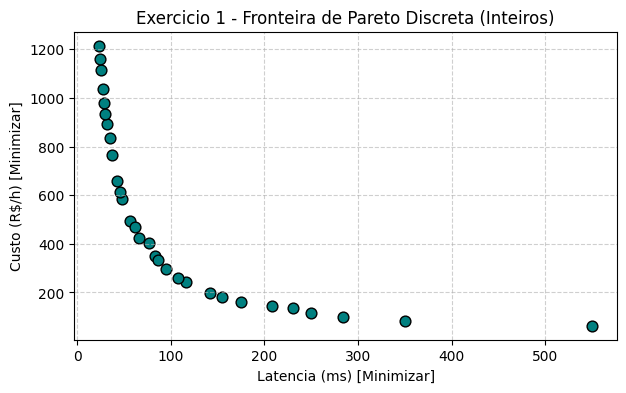

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.repair.rounding import RoundingRepair
from pymoo.optimize import minimize

class SOCInteiroProblem(ElementwiseProblem):
    def __init__(self):
        # x1: Pods (1 a 30), x2: Analistas de Nivel 2 (1 a 15) -> Ambos inteiros!
        super().__init__(
            n_var=2,
            n_obj=2,
            xl=np.array([1, 1]),
            xu=np.array([30, 15]),
            vtype=int
        )

    def _evaluate(self, x, out, *args, **kwargs):
        pods, analistas = x[0], x[1]
        f1_latencia = (400.0 / pods) + (150.0 / analistas)
        f2_custo = (pods * 18.0) + (analistas * 45.0)
        out["F"] = [f1_latencia, f2_custo]

algorithm = NSGA2(
    pop_size=30,
    sampling=IntegerRandomSampling(),
    crossover=SBX(prob=0.9, eta=15, vtype=float, repair=RoundingRepair()),
    mutation=PM(prob=0.2, eta=20, vtype=float, repair=RoundingRepair()),
    eliminate_duplicates=True
)

res1 = minimize(SOCInteiroProblem(), algorithm, termination=('n_gen', 40), seed=42)

print("Amostra de 5 solucoes inteiras encontradas (Pods, Analistas):")
for sol_x, sol_f in zip(res1.X[:5], res1.F[:5]):
    print(f"Pods: {sol_x[0]:2d} | Analistas: {sol_x[1]:2d} => Latencia: {sol_f[0]:6.2f}ms | Custo: R$ {sol_f[1]:6.2f}")

plt.figure(figsize=(7, 4))
plt.scatter(res1.F[:, 0], res1.F[:, 1], color='teal', s=60, edgecolor='black')
plt.title("Exercicio 1 - Fronteira de Pareto Discreta (Inteiros)")
plt.xlabel("Latencia (ms) [Minimizar]")
plt.ylabel("Custo (R$/h) [Minimizar]")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()